# Computation of DOP and Transmitter Selection

Satellite geometry affects how measurement errors translate into position errors. This notebook uses a small two-dimensional example to compare the geometry of several transmitter subsets and see how it changes the Position Dilution of Precision (PDOP).

The receiver is at the origin and four transmitters are placed at fixed coordinates. We will first plot the layout, then compute a geometry-only score for all transmitters and for three possible subsets. The goal is to compare the layouts—not to estimate a position or model real satellite orbits.

In [2]:
import numpy as np


# Transmitter position
T = np.array([
    [5, 2],
    [-2, 4],
    [0, -4],
    [7, 3],
])

# Receiver position
R = np.array([0, 0])

## Visualizing the transmitter positions

Each point represents a transmitter and the cross marks the receiver. The directions from the receiver to the transmitters—not simply their distances—are what shape the geometry score. A well-spread set of directions generally constrains the receiver position more evenly than transmitters clustered in similar directions.

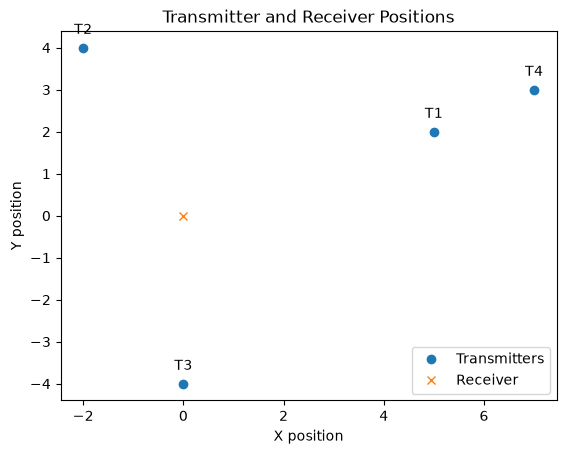

In [4]:
import matplotlib.pyplot as plt


fig, ax = plt.subplots()
ax.plot(T[:, 0], T[:, 1], 'o', label='Transmitters')
ax.plot(R[0], R[1], 'x', label='Receiver')
ax.set_title('Transmitter and Receiver Positions')
ax.set_xlabel('X position')
ax.set_ylabel('Y position')

for i, (x, y) in enumerate(T):
    ax.annotate(f'T{i+1}', (x, y), textcoords="offset points", xytext=(0,10), ha='center')

plt.legend()
plt.show()

## Compute the DOP

For each transmitter, the code forms a unit line-of-sight vector from the receiver to that transmitter. Stacking those vectors gives the geometry matrix $G$. Under the simplifying assumption of independent, equally noisy range measurements, the position covariance due to geometry is proportional to

$$Q = (G^T G)^{-1}.$$

The DOP is $\sqrt{\operatorname{trace}(Q)}$: smaller values mean the measurement directions amplify range noise less. The examples compare these choices:

1. All transmitters
2. Transmitters [1, 2, 3]
3. Transmitters [2, 3, 4]
4. Transmitters [1, 3, 4]

> **Scope note:** this is a two-dimensional, position-only model. It omits the receiver clock unknown and the vertical coordinate used in a full GNSS solution, so interpret the result as a simplified 2D PDOP-style geometry score rather than a complete real-world GNSS PDOP.

In [6]:
def compute_pdop(transmitters, receiver, transmitter_indices=None):
    """
    Compute the Position Dilution of Precision (PDOP) for a given set of transmitters and a receiver.

    Parameters:
    transmitters (np.ndarray): An Nx2 array of transmitter positions.
    receiver (np.ndarray): A 1x2 array of the receiver position.
    transmitter_indices (list, optional): A list of indices specifying which transmitters to use.
                                           If None, all transmitters are used.

    Returns:
    float: The computed PDOP value.
    """
    # Compute the geometry matrix G
    G = []

    transmitters_to_use = transmitters if transmitter_indices is None else transmitters[transmitter_indices]

    for t in transmitters_to_use:
        distance = np.linalg.norm(t - receiver)
        unit_vector = (t - receiver) / distance
        G.append(unit_vector)

    G = np.array(G)

    # Compute the covariance matrix
    Q = np.linalg.inv(G.T @ G)

    # PDOP is the square root of the trace of the covariance matrix
    pdop = np.sqrt(np.trace(Q))

    return pdop

In [7]:
scenarios = [
    None,  # All transmitters
    [0, 1, 2],  # Transmitters 1, 2, 3
    [1, 2, 3],  # Transmitters 2, 3, 4
    [0, 2, 3],  # Transmitters 1, 3, 4
]

for i, scenario in enumerate(scenarios):
    pdop = compute_pdop(T, R, scenario)
    if scenario is None:
        scenario_str = "All transmitters"
    else:
        scenario_str = f"Transmitters {[s + 1 for s in scenario]}"
    print(f"PDOP for {scenario_str}: {pdop:.4f}")

PDOP for All transmitters: 1.0131
PDOP for Transmitters [1, 2, 3]: 1.2082
PDOP for Transmitters [2, 3, 4]: 1.2123
PDOP for Transmitters [1, 3, 4]: 1.3255


## Interpreting the results

The lowest DOP is obtained when all four transmitters are used (about 1.0131). Among the three-transmitter subsets, [1, 2, 3] is slightly better than [2, 3, 4], while [1, 3, 4] has the largest DOP. This illustrates that adding another usable measurement can improve the geometry, but when choosing a subset, the directions of the selected transmitters matter more than how far away they are.

These values describe only geometric amplification under equal measurement quality. They do not include multipath, atmospheric errors, transmitter-specific uncertainty, or other effects that influence actual positioning accuracy.